# 03 · Análisis exploratorio de datos (EDA)

Entrada: `datos-procesados/dengue_limpio.csv`, generado en `02_limpieza.ipynb` (una fila por caso **confirmado**, variables ya recodificadas a 1/0).

Objetivo: entender la variable objetivo `DEFUNCION` y su relación con cada predictor **antes** de ajustar la regresión logística, y detectar problemas que afecten al modelo (desbalance, separación, colinealidad, no linealidad de la edad, inconsistencias).

| Sección | Pregunta |
|---|---|
| 1 · Panorama | ¿Qué hay en la base? ¿Faltantes, duplicados, rangos? |
| 2 · Variable objetivo | ¿Qué tan desbalanceada está `DEFUNCION`? |
| 3 · Edad | ¿Cómo cambia la mortalidad con la edad? ¿Es lineal en el logit? |
| 4 · Variables binarias | Prevalencia, mortalidad, razón de momios cruda y prueba de asociación |
| 5 · Serotipo | Mortalidad por serotipo (referencia DENV1) |
| 6 · Mes de inicio de síntomas | Estacionalidad de casos y de mortalidad |
| 7 · Relaciones entre predictores | Correlaciones y VIF (colinealidad) |
| 8 · Interacciones | ¿El efecto de la edad depende de la hospitalización? |
| 9 · Conclusiones | Implicaciones para el modelo |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import statsmodels.api as sm
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.proportion import proportion_confint

pd.set_option("display.max_columns", 50)
DATA = Path("datos-procesados")

# Paleta (categórica validada para daltonismo): azul = sobrevivió, naranja = defunción
AZUL, NARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, GRIS = "#0b0b0b", "#52514e", "#d9d8d4"
SECUENCIAL = LinearSegmentedColormap.from_list("azul", ["#f0efec", "#86b6ef", "#2a78d6", "#0d366b"])
DIVERGENTE = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#eb6834"])

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "text.color": TINTA, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "figure.dpi": 110, "font.size": 10, "legend.frameon": False,
})
pct = mticker.PercentFormatter(1, decimals=1)

def wilson(muertes, casos):
    """Intervalo de confianza de Wilson al 95% para una proporción."""
    return proportion_confint(muertes, casos, alpha=0.05, method="wilson")

dengue = pd.read_csv(DATA / "dengue_limpio.csv")
print(f"{dengue.shape[0]:,} filas × {dengue.shape[1]} columnas")
dengue.head()

251,900 filas × 29 columnas


,ID_REGISTRO,DEFUNCION,HOMBRE,EDAD_ANOS,COSTERA,INDIGENA,HEMORRAGICOS,DIABETES,HIPERTENSION,ENFERMEDAD_RENAL,INMUNOSUPR,CIRROSIS_HEPATICA,EMBARAZO,HOSPITALIZADO,DENV2,DENV3,DENV4,SIN_SEROTIPO,MES_ENE,MES_FEB,MES_MAR,MES_ABR,MES_MAY,MES_JUN,MES_JUL,MES_AGO,MES_SEP,MES_NOV,MES_DIC
0,759431,1,1,22,1,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0
1,759683,0,1,36,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
2,759744,0,0,3,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0
3,759961,0,1,22,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0
4,760071,0,0,8,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0


## 1 · Panorama de la base
Tipos, faltantes, duplicados y rango de cada columna. Todas las columnas salvo `ID_REGISTRO` y `EDAD_ANOS` deben ser 0/1.

In [2]:
BINARIAS = ["HOMBRE", "COSTERA", "INDIGENA", "HEMORRAGICOS", "DIABETES", "HIPERTENSION",
            "ENFERMEDAD_RENAL", "INMUNOSUPR", "CIRROSIS_HEPATICA", "EMBARAZO", "HOSPITALIZADO"]
SEROTIPOS = ["DENV2", "DENV3", "DENV4", "SIN_SEROTIPO"]          # referencia: DENV1
MESES = [c for c in dengue.columns if c.startswith("MES_")]      # referencia: MES_OCT

assert dengue.ID_REGISTRO.is_unique
assert dengue.notna().all().all()
no_binarias = [c for c in dengue.columns if c not in ["ID_REGISTRO", "EDAD_ANOS"]
               and not set(dengue[c].unique()) <= {0, 1}]
assert not no_binarias, no_binarias

print("Duplicados de ID:", dengue.ID_REGISTRO.duplicated().sum(), "| Faltantes:", dengue.isna().sum().sum())
print(f"Filas idénticas (sin contar ID): {dengue.drop(columns='ID_REGISTRO').duplicated().sum():,}  "
      "← esperado: muchos pacientes comparten el mismo perfil 0/1 y edad")
dengue.drop(columns="ID_REGISTRO").describe().T[["mean", "std", "min", "max"]].round(3)

Duplicados de ID: 0 | Faltantes: 0
Filas idénticas (sin contar ID): 212,455  ← esperado: muchos pacientes comparten el mismo perfil 0/1 y edad


,mean,std,min,max
DEFUNCION,0.007,0.083,0.0,1.0
HOMBRE,0.448,0.497,0.0,1.0
EDAD_ANOS,28.488,17.815,0.0,112.0
COSTERA,0.701,0.458,0.0,1.0
INDIGENA,0.033,0.179,0.0,1.0
HEMORRAGICOS,0.009,0.095,0.0,1.0
DIABETES,0.029,0.167,0.0,1.0
HIPERTENSION,0.023,0.151,0.0,1.0
ENFERMEDAD_RENAL,0.003,0.050,0.0,1.0
INMUNOSUPR,0.001,0.038,0.0,1.0


## 2 · Variable objetivo: `DEFUNCION`

Defunciones: 1,763 de 251,900 = 0.70%  (IC 95%: 0.67% – 0.73%)
Razón sobrevivientes : muertes ≈ 142 : 1


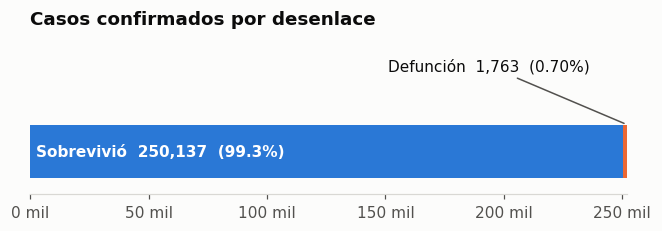

In [3]:
n, muertes = len(dengue), dengue.DEFUNCION.sum()
lo, hi = wilson(muertes, n)
print(f"Defunciones: {muertes:,} de {n:,} = {muertes / n:.2%}  (IC 95%: {lo:.2%} – {hi:.2%})")
print(f"Razón sobrevivientes : muertes ≈ {(n - muertes) / muertes:.0f} : 1")

fig, ax = plt.subplots(figsize=(7, 1.9))
ax.barh([""], [n - muertes], color=AZUL, height=0.5)
ax.barh([""], [muertes], left=[n - muertes], color=NARANJA, height=0.5)
ax.set_xlim(0, n); ax.set_ylim(-0.4, 1.1)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x / 1e3:,.0f} mil"))
ax.text(0.01 * n, 0, f"Sobrevivió  {n - muertes:,}  ({1 - muertes / n:.1%})", va="center", color="white", weight="bold")
ax.annotate(f"Defunción  {muertes:,}  ({muertes / n:.2%})", xy=(n, 0.25), xytext=(0.6 * n, 0.75),
            arrowprops=dict(arrowstyle="-", color=TINTA_2), color=TINTA)
ax.set_title("Casos confirmados por desenlace")
ax.grid(False); ax.spines["left"].set_visible(False); ax.tick_params(left=False)
plt.show()

**Lectura:** la clase positiva es muy rara (menos de 1 de cada 100 casos). Consecuencias para el modelo:
- La *exactitud* (accuracy) no sirve como métrica: predecir "nadie muere" ya acierta >99%. Conviene evaluar con AUC-ROC, AUC-PR, sensibilidad/especificidad y calibración.
- El umbral de clasificación de 0.5 no tiene sentido; hay que elegirlo según el costo de los errores.
- Con ~1,700 eventos hay suficientes casos para ~30 predictores (regla de ≥10–20 eventos por variable), pero las categorías raras pueden tener muy pocas muertes (ver sección 4).

## 3 · Edad (`EDAD_ANOS`)
Única variable numérica. Se revisa su distribución por desenlace, la mortalidad por grupo de edad y si la relación con el **logit** de la mortalidad es aproximadamente lineal (supuesto de la regresión logística).

               count  mean   std  min   25%   50%   75%    max
DEFUNCION                                                     
Sobrevivió  250137.0  28.4  17.7  0.0  14.0  25.0  40.0  112.0
Defunción     1763.0  39.4  25.1  0.0  16.0  37.0  59.5   99.0



Mann-Whitney U (edad muertos vs. sobrevivientes): p = 9.09e-66
Edades extremas: 1,632 con 0 años, 8 con más de 100 años


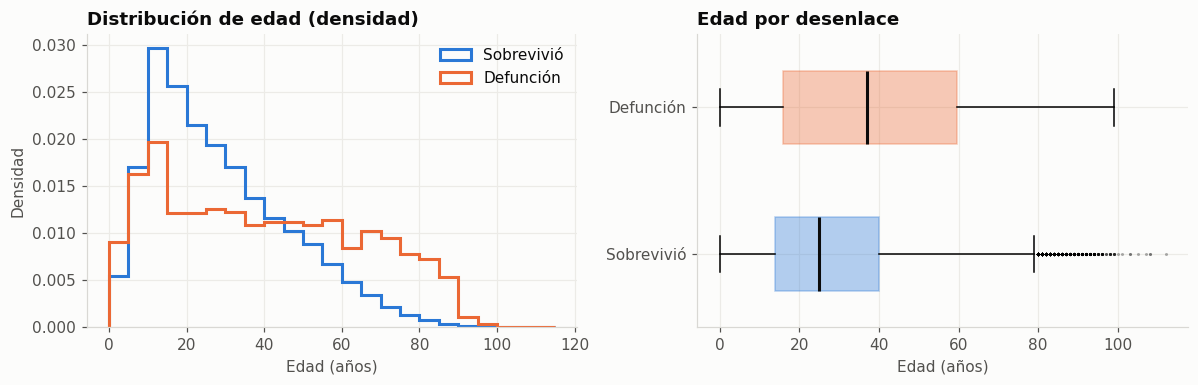

In [4]:
print(dengue.groupby("DEFUNCION").EDAD_ANOS.describe().rename(index={0: "Sobrevivió", 1: "Defunción"}).round(1))
u = stats.mannwhitneyu(dengue.EDAD_ANOS[dengue.DEFUNCION == 1], dengue.EDAD_ANOS[dengue.DEFUNCION == 0])
print(f"\nMann-Whitney U (edad muertos vs. sobrevivientes): p = {u.pvalue:.2e}")
print(f"Edades extremas: {(dengue.EDAD_ANOS == 0).sum():,} con 0 años, {(dengue.EDAD_ANOS > 100).sum()} con más de 100 años")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.arange(0, dengue.EDAD_ANOS.max() + 5, 5)
for valor, color, etiqueta in [(0, AZUL, "Sobrevivió"), (1, NARANJA, "Defunción")]:
    axes[0].hist(dengue.EDAD_ANOS[dengue.DEFUNCION == valor], bins=bins, density=True, histtype="step",
                 linewidth=2, color=color, label=etiqueta)
axes[0].set(title="Distribución de edad (densidad)", xlabel="Edad (años)", ylabel="Densidad")
axes[0].legend()

bp = axes[1].boxplot([dengue.EDAD_ANOS[dengue.DEFUNCION == 0], dengue.EDAD_ANOS[dengue.DEFUNCION == 1]],
                     vert=False, widths=0.5, patch_artist=True, flierprops=dict(marker=".", markersize=2, alpha=0.3))
for caja, color in zip(bp["boxes"], [AZUL, NARANJA]):
    caja.set(facecolor=color, alpha=0.35, edgecolor=color)
for med in bp["medians"]:
    med.set(color=TINTA, linewidth=2)
axes[1].set_yticks([1, 2], ["Sobrevivió", "Defunción"])
axes[1].set(title="Edad por desenlace", xlabel="Edad (años)")
plt.tight_layout(); plt.show()

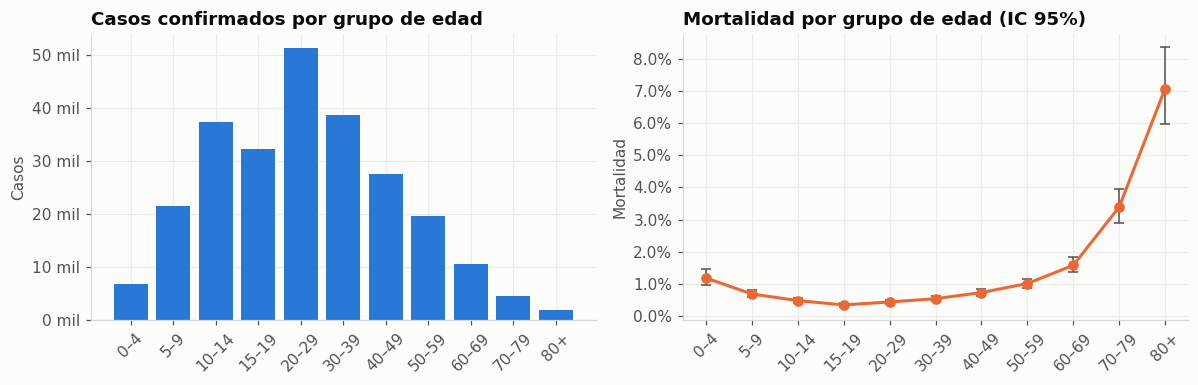

GRUPO_EDAD,0–4,5–9,10–14,15–19,20–29,30–39,40–49,50–59,60–69,70–79,80+
casos,6828,21399,37311,32252,51395,38726,27576,19691,10458,4514,1750
muertes,80,144,174,107,218,204,198,197,164,153,124
mortalidad,1.17%,0.67%,0.47%,0.33%,0.42%,0.53%,0.72%,1.00%,1.57%,3.39%,7.09%


In [5]:
cortes = [0, 5, 10, 15, 20, 30, 40, 50, 60, 70, 80, 200]
etiquetas = ["0–4", "5–9", "10–14", "15–19", "20–29", "30–39", "40–49", "50–59", "60–69", "70–79", "80+"]
dengue_edad = dengue.assign(GRUPO_EDAD=pd.cut(dengue.EDAD_ANOS, cortes, right=False, labels=etiquetas))

por_edad = dengue_edad.groupby("GRUPO_EDAD", observed=True).DEFUNCION.agg(casos="size", muertes="sum")
por_edad["mortalidad"] = por_edad.muertes / por_edad.casos
por_edad["ic_bajo"], por_edad["ic_alto"] = wilson(por_edad.muertes, por_edad.casos)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(por_edad.index.astype(str), por_edad.casos, color=AZUL, width=0.8)
axes[0].set(title="Casos confirmados por grupo de edad", ylabel="Casos")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x / 1e3:,.0f} mil"))

x = np.arange(len(por_edad))
axes[1].errorbar(x, por_edad.mortalidad, yerr=[por_edad.mortalidad - por_edad.ic_bajo, por_edad.ic_alto - por_edad.mortalidad],
                 fmt="o-", color=NARANJA, linewidth=2, markersize=6, capsize=3, ecolor=TINTA_2, elinewidth=1)
axes[1].set_xticks(x, por_edad.index.astype(str))
axes[1].yaxis.set_major_formatter(pct)
axes[1].set(title="Mortalidad por grupo de edad (IC 95%)", ylabel="Mortalidad")
for ax in axes: ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

por_edad.assign(mortalidad=por_edad.mortalidad.map("{:.2%}".format)).drop(columns=["ic_bajo", "ic_alto"]).T

### ¿Es lineal la edad en el logit?
La regresión logística supone que el **logit** (log-momios) de morir cambia linealmente con la edad. Se compara el logit empírico por grupos de 5 años de edad (tamaño del punto ∝ casos) contra el ajuste lineal de un modelo univariado.

OR por cada 10 años de edad (univariado): 1.34
Prueba de razón de verosimilitud lineal vs. cuadrático: LR = 289.8, p = 5.54e-65
AIC lineal = 20,428 | AIC cuadrático = 20,140


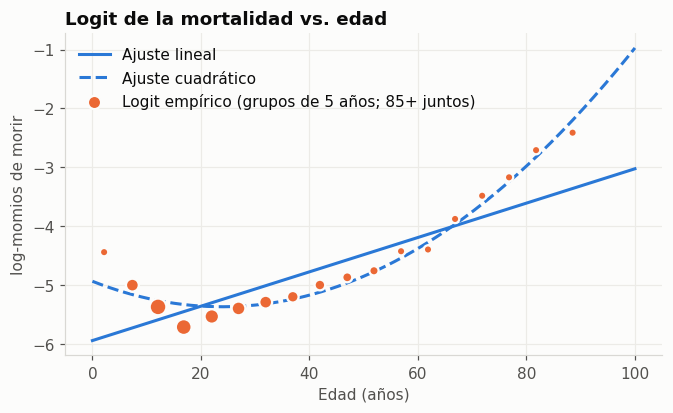

In [6]:
grupos5 = pd.cut(dengue.EDAD_ANOS, list(range(0, 90, 5)) + [200], right=False)
emp = dengue.groupby(grupos5, observed=True).agg(edad=("EDAD_ANOS", "mean"), p=("DEFUNCION", "mean"), n=("DEFUNCION", "size"))
emp = emp[emp.p > 0]
emp["logit"] = np.log(emp.p / (1 - emp.p))

X_lin = sm.add_constant(dengue[["EDAD_ANOS"]])
m_lin = sm.Logit(dengue.DEFUNCION, X_lin).fit(disp=0)
X_cuad = X_lin.assign(EDAD_2=dengue.EDAD_ANOS ** 2)
m_cuad = sm.Logit(dengue.DEFUNCION, X_cuad).fit(disp=0)
lr = 2 * (m_cuad.llf - m_lin.llf)

print(f"OR por cada 10 años de edad (univariado): {np.exp(10 * m_lin.params.EDAD_ANOS):.2f}")
print(f"Prueba de razón de verosimilitud lineal vs. cuadrático: LR = {lr:.1f}, p = {stats.chi2.sf(lr, 1):.2e}")
print(f"AIC lineal = {m_lin.aic:,.0f} | AIC cuadrático = {m_cuad.aic:,.0f}")

malla = np.linspace(0, 100, 200)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(malla, m_lin.params.const + m_lin.params.EDAD_ANOS * malla, color=AZUL, linewidth=2, label="Ajuste lineal")
ax.plot(malla, m_cuad.params.const + m_cuad.params.EDAD_ANOS * malla + m_cuad.params.EDAD_2 * malla ** 2,
        color=AZUL, linewidth=2, linestyle="--", label="Ajuste cuadrático")
ax.scatter(emp.edad, emp.logit, s=np.clip(emp.n / 300, 30, 120), color=NARANJA, edgecolor="#fcfcfb", linewidth=1.5, zorder=3, label="Logit empírico (grupos de 5 años; 85+ juntos)")
ax.set(title="Logit de la mortalidad vs. edad", xlabel="Edad (años)", ylabel="log-momios de morir")
ax.legend(); plt.show()

## 4 · Variables binarias
Para cada predictor 0/1: cuántos pacientes lo tienen, la mortalidad con y sin él, la **razón de momios cruda** (OR, sin ajustar por las demás variables) con IC 95%, y la prueba de asociación (χ², o exacta de Fisher si alguna celda esperada es < 5).

In [7]:
def resumen_binaria(col):
    t = pd.crosstab(dengue[col], dengue.DEFUNCION).reindex(index=[1, 0], columns=[1, 0], fill_value=0)
    a, b, c, d = t.values.ravel()          # a: expuesto-murió, b: expuesto-vivió, c: no expuesto-murió, d: no expuesto-vivió
    tabla = sm.stats.Table2x2(t.values, shift_zeros=True)
    lo, hi = tabla.oddsratio_confint()
    esperadas = stats.contingency.expected_freq(t.values)
    if (esperadas < 5).any():
        p, prueba = stats.fisher_exact(t.values).pvalue, "Fisher"
    else:
        p, prueba = stats.chi2_contingency(t.values)[1], "χ²"
    return {"variable": col, "n_con": a + b, "% con": (a + b) / len(dengue), "muertes_con": a,
            "mort_con": a / (a + b) if a + b else np.nan, "mort_sin": c / (c + d),
            "OR": tabla.oddsratio, "OR_ic_bajo": lo, "OR_ic_alto": hi, "prueba": prueba, "p": p}

binarias = pd.DataFrame([resumen_binaria(c) for c in BINARIAS + SEROTIPOS]).set_index("variable")
binarias.loc[BINARIAS].sort_values("OR", ascending=False).style.format({
    "n_con": "{:,}", "% con": "{:.2%}", "muertes_con": "{:,}", "mort_con": "{:.2%}", "mort_sin": "{:.2%}",
    "OR": "{:.2f}", "OR_ic_bajo": "{:.2f}", "OR_ic_alto": "{:.2f}", "p": "{:.1e}"})

,n_con,% con,muertes_con,mort_con,mort_sin,OR,OR_ic_bajo,OR_ic_alto,prueba,p
variable,,,,,,,,,,
HOSPITALIZADO,"98,005",38.91%,"1,689",1.72%,0.05%,36.45,28.88,46.01,χ²,0.0e+00
ENFERMEDAD_RENAL,633,0.25%,77,12.16%,0.67%,20.50,16.08,26.14,Fisher,1.6e-68
CIRROSIS_HEPATICA,233,0.09%,12,5.15%,0.70%,7.75,4.33,13.88,Fisher,1.3e-07
INMUNOSUPR,371,0.15%,16,4.31%,0.69%,6.44,3.90,10.66,Fisher,1.4e-08
DIABETES,"7,253",2.88%,263,3.63%,0.61%,6.10,5.34,6.97,χ²,3.6e-201
HEMORRAGICOS,"2,287",0.91%,89,3.89%,0.67%,6.00,4.83,7.45,χ²,1.5e-74
HIPERTENSION,"5,918",2.35%,194,3.28%,0.64%,5.28,4.54,6.14,χ²,3.0e-127
COSTERA,"176,608",70.11%,"1,342",0.76%,0.56%,1.36,1.22,1.52,χ²,3.7e-08
INDIGENA,"8,348",3.31%,69,0.83%,0.70%,1.19,0.93,1.52,χ²,1.8e-01


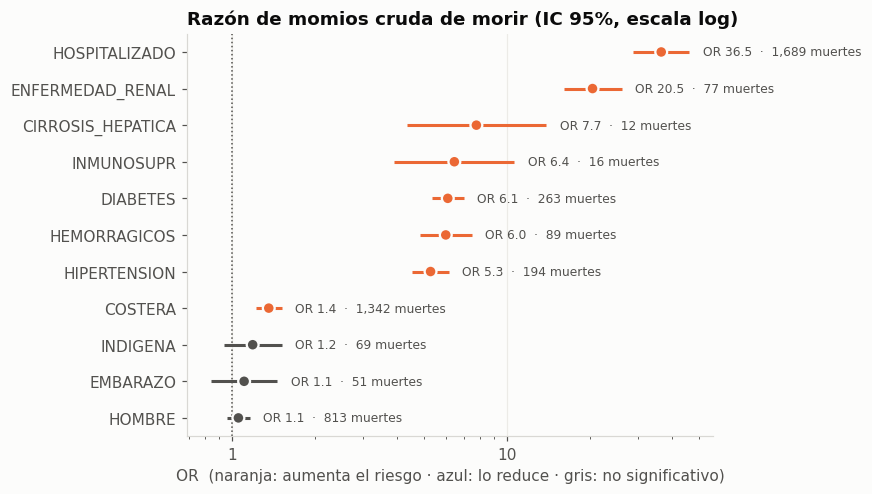

In [8]:
orden = binarias.loc[BINARIAS].sort_values("OR")
fig, ax = plt.subplots(figsize=(8, 4.6))
y = np.arange(len(orden))
color = [NARANJA if lo > 1 else AZUL if hi < 1 else TINTA_2 for lo, hi in zip(orden.OR_ic_bajo, orden.OR_ic_alto)]
ax.hlines(y, orden.OR_ic_bajo, orden.OR_ic_alto, color=color, linewidth=2)
ax.scatter(orden.OR, y, color=color, s=60, zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
ax.axvline(1, color=TINTA_2, linewidth=1, linestyle=":")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_yticks(y, orden.index)
for yi, (o, m) in enumerate(zip(orden.OR, orden.muertes_con)):
    ax.text(orden.OR_ic_alto.iloc[yi] * 1.12, yi, f"OR {o:.1f}  ·  {m:,} muertes", va="center", fontsize=8, color=TINTA_2)
ax.set(title="Razón de momios cruda de morir (IC 95%, escala log)", xlabel="OR  (naranja: aumenta el riesgo · azul: lo reduce · gris: no significativo)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### Revisiones de consistencia
- `EMBARAZO` solo debería ocurrir en mujeres en edad fértil.
- Variables con muy pocos casos o pocas muertes pueden producir coeficientes inestables o **separación** (una combinación que predice perfectamente el desenlace) en el modelo.

In [9]:
emb = dengue[dengue.EMBARAZO == 1]
print(f"Embarazadas: {len(emb):,}")
print(f"  ...registradas como hombre: {emb.HOMBRE.sum()}")
print(f"  ...con edad < 10 o > 55 años: {((emb.EDAD_ANOS < 10) | (emb.EDAD_ANOS > 55)).sum()}")
print(f"  rango de edad: {emb.EDAD_ANOS.min()}–{emb.EDAD_ANOS.max()} años")

mujeres_fertiles = dengue[(dengue.HOMBRE == 0) & dengue.EDAD_ANOS.between(12, 50)]
print(f"\nMortalidad en mujeres de 12–50 años: embarazadas {mujeres_fertiles[mujeres_fertiles.EMBARAZO == 1].DEFUNCION.mean():.2%} "
      f"vs. no embarazadas {mujeres_fertiles[mujeres_fertiles.EMBARAZO == 0].DEFUNCION.mean():.2%}")

pocas = binarias.loc[BINARIAS + SEROTIPOS].query("muertes_con < 20")
print("\nVariables con menos de 20 muertes en la categoría 1 (riesgo de estimaciones inestables):")
print(pocas[["n_con", "muertes_con"]].to_string() if len(pocas) else "  ninguna")

print(f"\nMuertes no hospitalizadas: {((dengue.DEFUNCION == 1) & (dengue.HOSPITALIZADO == 0)).sum()} "
      f"de {dengue.DEFUNCION.sum():,} ({((dengue.DEFUNCION == 1) & (dengue.HOSPITALIZADO == 0)).sum() / dengue.DEFUNCION.sum():.1%})")

Embarazadas: 6,602
  ...registradas como hombre: 0
  ...con edad < 10 o > 55 años: 6
  rango de edad: 0–49 años

Mortalidad en mujeres de 12–50 años: embarazadas 0.77% vs. no embarazadas 0.50%

Variables con menos de 20 muertes en la categoría 1 (riesgo de estimaciones inestables):
                   n_con  muertes_con
variable                             
INMUNOSUPR           371           16
CIRROSIS_HEPATICA    233           12
DENV4               1396           12

Muertes no hospitalizadas: 74 de 1,763 (4.2%)


## 5 · Serotipo (`RESULTADO_PCR`)
Se reconstruye la categoría a partir de las dummies (todas en 0 = DENV1, la referencia).

χ² serotipo × defunción: 42.6, p = 1.2e-08


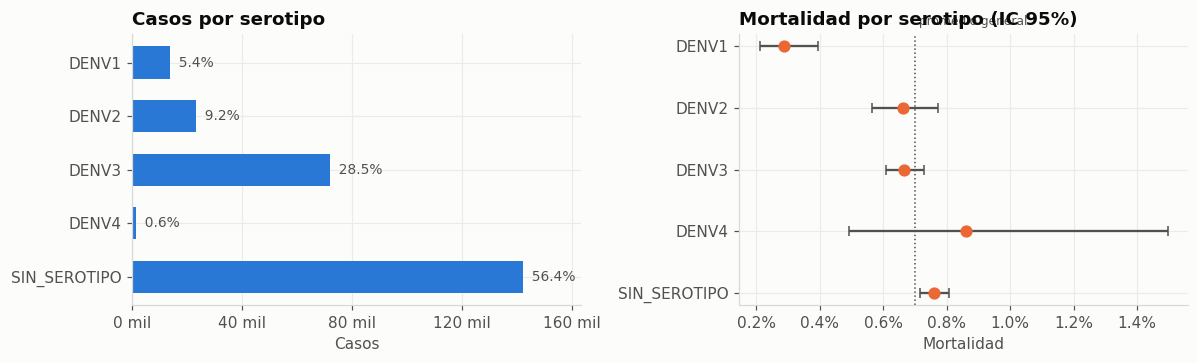

,casos,muertes,mortalidad
DENV1,13531,39,0.29%
DENV2,23139,153,0.66%
DENV3,71812,479,0.67%
DENV4,1396,12,0.86%
SIN_SEROTIPO,142022,1080,0.76%


In [10]:
serotipo = pd.Series("DENV1", index=dengue.index)
for s in SEROTIPOS:
    serotipo[dengue[s] == 1] = s
serotipo = pd.Categorical(serotipo, categories=["DENV1"] + SEROTIPOS)

por_sero = dengue.groupby(serotipo, observed=True).DEFUNCION.agg(casos="size", muertes="sum")
por_sero["mortalidad"] = por_sero.muertes / por_sero.casos
por_sero["ic_bajo"], por_sero["ic_alto"] = wilson(por_sero.muertes, por_sero.casos)
chi2, p_sero, *_ = stats.chi2_contingency(pd.crosstab(serotipo, dengue.DEFUNCION))
print(f"χ² serotipo × defunción: {chi2:.1f}, p = {p_sero:.1e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].barh(por_sero.index.astype(str), por_sero.casos, color=AZUL, height=0.6)
axes[0].invert_yaxis()
axes[0].set(title="Casos por serotipo", xlabel="Casos")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x / 1e3:,.0f} mil"))
for i, v in enumerate(por_sero.casos):
    axes[0].text(v, i, f"  {v / por_sero.casos.sum():.1%}", va="center", fontsize=9, color=TINTA_2)
axes[0].set_xlim(0, por_sero.casos.max() * 1.15)
axes[0].xaxis.set_major_locator(mticker.MaxNLocator(5))

axes[1].errorbar(por_sero.mortalidad, np.arange(len(por_sero)),
                 xerr=[por_sero.mortalidad - por_sero.ic_bajo, por_sero.ic_alto - por_sero.mortalidad],
                 fmt="o", color=NARANJA, markersize=7, capsize=3, ecolor=TINTA_2)
axes[1].set_yticks(range(len(por_sero)), por_sero.index.astype(str))
axes[1].invert_yaxis()
axes[1].axvline(dengue.DEFUNCION.mean(), color=TINTA_2, linestyle=":", linewidth=1)
axes[1].text(dengue.DEFUNCION.mean(), -0.35, " promedio general", fontsize=8, color=TINTA_2)
axes[1].xaxis.set_major_formatter(pct)
axes[1].set(title="Mortalidad por serotipo (IC 95%)", xlabel="Mortalidad")
plt.tight_layout(); plt.show()
por_sero.assign(mortalidad=por_sero.mortalidad.map("{:.2%}".format)).drop(columns=["ic_bajo", "ic_alto"])

## 6 · Mes de inicio de síntomas
Se reconstruye el mes a partir de las dummies (todas en 0 = octubre, la referencia). Casos y mortalidad van en gráficas separadas porque tienen escalas distintas.

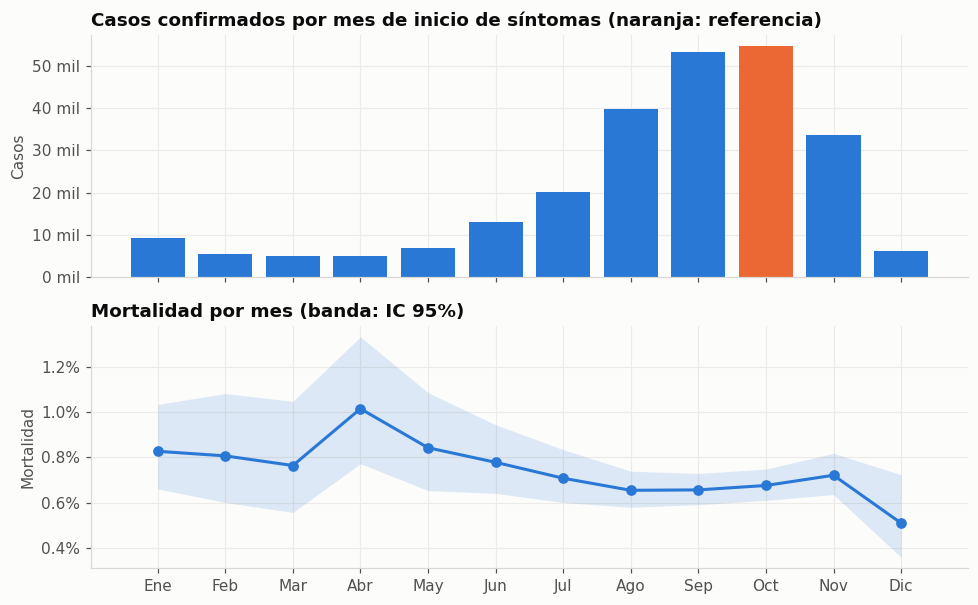

,MES_ENE,MES_FEB,MES_MAR,MES_ABR,MES_MAY,MES_JUN,MES_JUL,MES_AGO,MES_SEP,MES_OCT,MES_NOV,MES_DIC
casos,9194,5456,4974,5029,7005,13110,20056,39709,53148,54583,33561,6075
muertes,76,44,38,51,59,102,142,260,349,369,242,31
mortalidad,0.83%,0.81%,0.76%,1.01%,0.84%,0.78%,0.71%,0.65%,0.66%,0.68%,0.72%,0.51%


In [11]:
NOMBRES = ["MES_ENE", "MES_FEB", "MES_MAR", "MES_ABR", "MES_MAY", "MES_JUN",
           "MES_JUL", "MES_AGO", "MES_SEP", "MES_OCT", "MES_NOV", "MES_DIC"]
mes = pd.Series("MES_OCT", index=dengue.index)
for m in MESES:
    mes[dengue[m] == 1] = m
mes = pd.Categorical(mes, categories=NOMBRES)

por_mes = dengue.groupby(mes, observed=True).DEFUNCION.agg(casos="size", muertes="sum")
por_mes["mortalidad"] = por_mes.muertes / por_mes.casos
por_mes["ic_bajo"], por_mes["ic_alto"] = wilson(por_mes.muertes, por_mes.casos)
etq = [m.replace("MES_", "").capitalize() for m in por_mes.index]

fig, axes = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True)
axes[0].bar(etq, por_mes.casos, color=[NARANJA if m == "MES_OCT" else AZUL for m in por_mes.index], width=0.8)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x / 1e3:,.0f} mil"))
axes[0].set(title="Casos confirmados por mes de inicio de síntomas (naranja: referencia)", ylabel="Casos")
x = np.arange(12)
axes[1].fill_between(x, por_mes.ic_bajo, por_mes.ic_alto, color=AZUL, alpha=0.15, linewidth=0)
axes[1].plot(x, por_mes.mortalidad, "o-", color=AZUL, linewidth=2, markersize=6)
axes[1].yaxis.set_major_formatter(pct)
axes[1].set(title="Mortalidad por mes (banda: IC 95%)", ylabel="Mortalidad")
plt.tight_layout(); plt.show()
por_mes.assign(mortalidad=por_mes.mortalidad.map("{:.2%}".format)).drop(columns=["ic_bajo", "ic_alto"]).T

## 7 · Relaciones entre predictores
**Correlación** (para variables 0/1, la correlación de Pearson es el coeficiente φ) y **factor de inflación de varianza** (VIF). Un VIF > 5–10 indica colinealidad que infla los errores estándar del modelo.

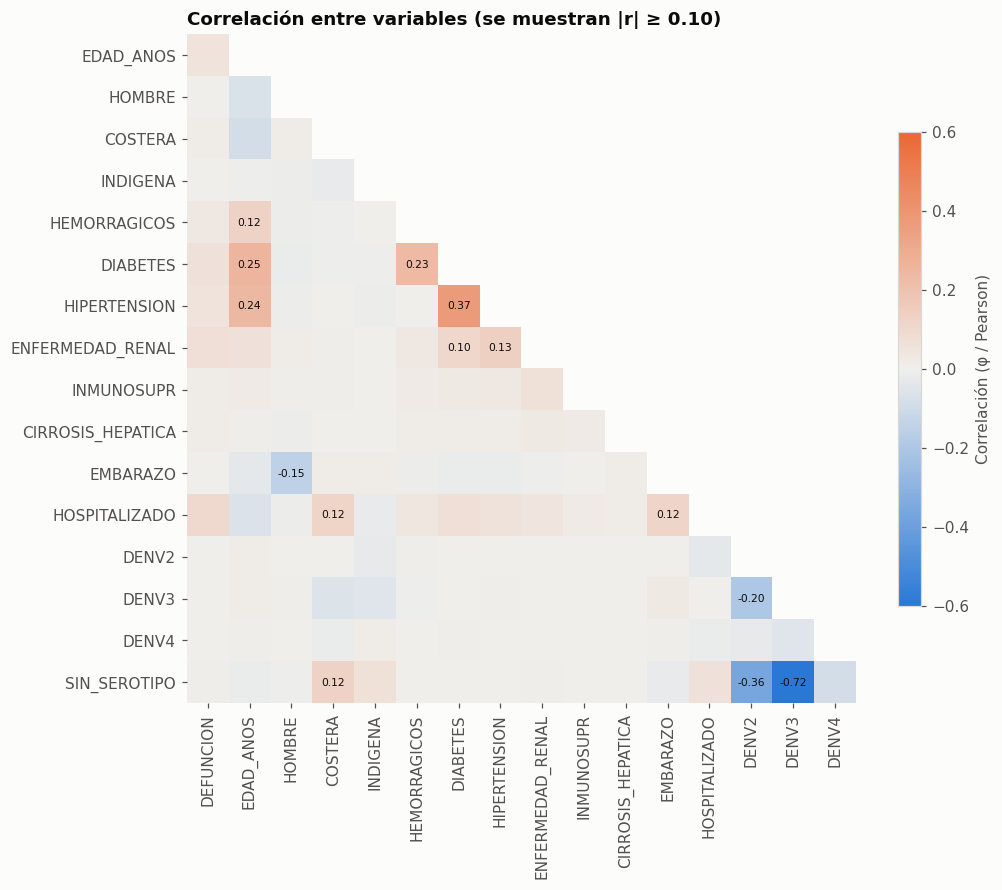

Pares con mayor |correlación|:
DENV3         SIN_SEROTIPO   -0.718
DIABETES      HIPERTENSION    0.367
DENV2         SIN_SEROTIPO   -0.362
EDAD_ANOS     DIABETES        0.254
              HIPERTENSION    0.243
HEMORRAGICOS  DIABETES        0.233
DENV2         DENV3          -0.201
HOMBRE        EMBARAZO       -0.148


In [12]:
PREDICTORES = ["EDAD_ANOS"] + BINARIAS + SEROTIPOS
corr = dengue[["DEFUNCION"] + PREDICTORES].corr()

fig, ax = plt.subplots(figsize=(9.5, 8))
mascara = np.triu(np.ones_like(corr, dtype=bool), k=0)
im = ax.imshow(np.ma.masked_where(mascara, corr)[1:, :-1], cmap=DIVERGENTE, vmin=-0.6, vmax=0.6)
ax.set_xticks(range(len(corr) - 1), corr.columns[:-1], rotation=90)
ax.set_yticks(range(len(corr) - 1), corr.columns[1:])
for i in range(len(corr)):
    for j in range(i):
        if abs(corr.iat[i, j]) >= 0.1:
            ax.text(j, i - 1, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7, color=TINTA)
ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="Correlación (φ / Pearson)")
ax.set_title("Correlación entre variables (se muestran |r| ≥ 0.10)")
plt.tight_layout(); plt.show()

pares = corr.where(~np.tril(np.ones_like(corr, dtype=bool))).stack().rename("r")
print("Pares con mayor |correlación|:")
print(pares.reindex(pares.abs().sort_values(ascending=False).index).head(8).round(3).to_string())

In [13]:
X = sm.add_constant(dengue[PREDICTORES + MESES].astype(float))
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
                index=X.columns[1:], name="VIF").sort_values(ascending=False)
print(f"VIF máximo: {vif.max():.2f} ({vif.idxmax()}) | variables con VIF > 5: {(vif > 5).sum()}")
vif.round(2).to_frame().T

VIF máximo: 5.18 (SIN_SEROTIPO) | variables con VIF > 5: 1


,SIN_SEROTIPO,DENV3,DENV2,MES_SEP,MES_AGO,MES_NOV,DIABETES,MES_JUL,HIPERTENSION,MES_JUN,MES_ENE,EDAD_ANOS,MES_MAY,DENV4,MES_DIC,MES_FEB,COSTERA,MES_MAR,HEMORRAGICOS,MES_ABR,HOSPITALIZADO,EMBARAZO,HOMBRE,ENFERMEDAD_RENAL,INDIGENA,INMUNOSUPR,CIRROSIS_HEPATICA
VIF,5.18,4.6,2.5,1.56,1.46,1.4,1.27,1.26,1.22,1.18,1.14,1.14,1.1,1.1,1.09,1.09,1.08,1.08,1.08,1.08,1.05,1.04,1.03,1.03,1.01,1.01,1.0


## 8 · Interacciones
La hospitalización es el predictor más fuerte. ¿El aumento de la mortalidad con la edad es igual en ambulatorios y hospitalizados?

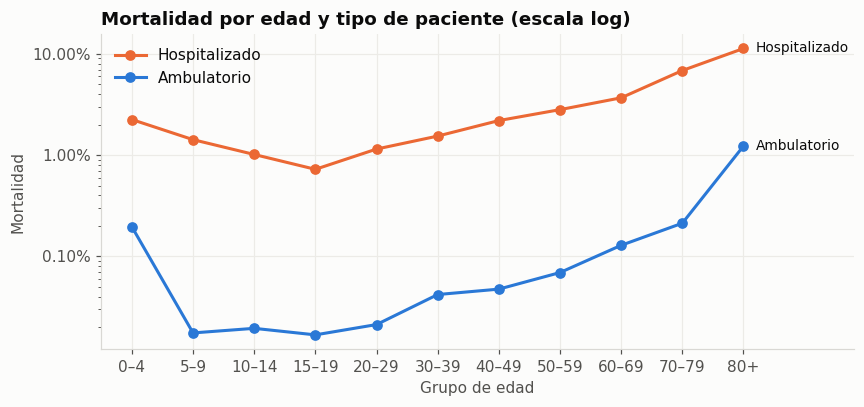

GRUPO_EDAD,0–4,5–9,10–14,15–19,20–29,30–39,40–49,50–59,60–69,70–79,80+
HOSPITALIZADO,,,,,,,,,,,
0,0.20%,0.02%,0.02%,0.02%,0.02%,0.04%,0.05%,0.07%,0.13%,0.21%,1.23%
1,2.24%,1.42%,1.01%,0.72%,1.15%,1.54%,2.19%,2.81%,3.68%,6.85%,11.30%


In [14]:
inter = (dengue_edad.groupby(["HOSPITALIZADO", "GRUPO_EDAD"], observed=True).DEFUNCION
         .agg(casos="size", muertes="sum").reset_index())
inter["mortalidad"] = inter.muertes / inter.casos

fig, ax = plt.subplots(figsize=(8, 3.8))
for h, color, etiqueta in [(1, NARANJA, "Hospitalizado"), (0, AZUL, "Ambulatorio")]:
    sub = inter[inter.HOSPITALIZADO == h]
    ax.plot(sub.GRUPO_EDAD.astype(str), sub.mortalidad, "o-", color=color, linewidth=2, markersize=6, label=etiqueta)
    ax.text(len(sub) - 0.8, sub.mortalidad.iloc[-1], etiqueta, color=TINTA, va="center", fontsize=9)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=2))
ax.set(title="Mortalidad por edad y tipo de paciente (escala log)", ylabel="Mortalidad", xlabel="Grupo de edad")
ax.set_xlim(-0.5, len(etiquetas) + 0.8)
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
inter.pivot(index="HOSPITALIZADO", columns="GRUPO_EDAD", values="mortalidad").map("{:.2%}".format)

In [15]:
# Prueba formal: modelo con interacción EDAD × HOSPITALIZADO vs. sin ella
base = sm.add_constant(dengue[["EDAD_ANOS", "HOSPITALIZADO"]].astype(float))
m0 = sm.Logit(dengue.DEFUNCION, base).fit(disp=0)
m1 = sm.Logit(dengue.DEFUNCION, base.assign(EDAD_x_HOSP=dengue.EDAD_ANOS * dengue.HOSPITALIZADO)).fit(disp=0)
lr = 2 * (m1.llf - m0.llf)
print(f"LR interacción edad × hospitalizado = {lr:.1f}, p = {stats.chi2.sf(lr, 1):.2e}")
print(m1.summary2().tables[1][["Coef.", "P>|z|"]].round(4))

LR interacción edad × hospitalizado = 3.5, p = 6.19e-02


                Coef.   P>|z|
const         -9.0779  0.0000
EDAD_ANOS      0.0399  0.0000
HOSPITALIZADO  4.0992  0.0000
EDAD_x_HOSP   -0.0112  0.0608


## 9 · Conclusiones para el modelo

**Calidad de la base.** 251,900 casos confirmados, sin faltantes ni IDs duplicados, todas las variables 0/1 válidas. No hay embarazadas registradas como hombre; solo 6 embarazos fuera de 10–55 años (incluye edad 0, probable error de captura, impacto despreciable).

**Variable objetivo.** 1,763 defunciones (0.70%, ~1 de cada 142). Evaluar con AUC-ROC / AUC-PR, sensibilidad, especificidad y calibración, no con exactitud; elegir el umbral de clasificación explícitamente.

**Edad.** Los fallecidos son mayores (mediana 37 vs. 25 años). La mortalidad tiene forma de **U/J**: alta en menores de 5 años (1.2%), mínima a los 15–19 (0.3%) y creciente después (7.1% en 80+). **La edad no es lineal en el logit** (LR lineal vs. cuadrático p < 1e-60; AIC baja ~290). → Usar edad + edad², splines, o grupos de edad.

**Predictores binarios (OR crudas).** Fuertemente asociados: hospitalización (OR ≈ 37), enfermedad renal (≈ 20), cirrosis (≈ 8), inmunosupresión (≈ 6), diabetes (≈ 6), hemorrágicos (≈ 6), hipertensión (≈ 5) y, en menor grado, estado costero (≈ 1.4). Sexo, indígena y embarazo **no** muestran asociación cruda significativa (pueden conservarse como controles; embarazo sí se asocia al compararse solo contra mujeres de 12–50 años: 0.77% vs. 0.50%).

**⚠️ Hospitalización.** El 96% de las muertes estuvo hospitalizado y es, por mucho, el predictor más fuerte. Probablemente es una **consecuencia de la gravedad**, no una causa: si el objetivo es explicar factores de riesgo del paciente, incluirla absorbe el efecto de las comorbilidades. Se recomienda ajustar el modelo **con y sin** `HOSPITALIZADO` y discutirlo. La interacción edad × hospitalización no es significativa (p ≈ 0.06).

**Categorías con pocos eventos.** Inmunosupresión (16 muertes), cirrosis (12) y DENV4 (12) tienen IC muy amplios; sus coeficientes serán imprecisos. Considerar agruparlas (p. ej. DENV4 con otro serotipo o una variable "comorbilidad grave") si dan problemas de convergencia.

**Serotipo.** DENV1 tiene la menor mortalidad (0.29%); DENV2, DENV3 y sin serotipo están entre 0.66% y 0.76% (χ² p ≈ 1e-8). Recordar que el serotipo está confundido con la época (ver notebook 02).

**Mes.** Los casos se concentran en agosto–noviembre (temporada de lluvias); la mortalidad es algo mayor fuera de temporada (ene–may ≈ 0.8–1.0%) y menor en pico (≈ 0.65%), aunque con IC que se traslapan.

**Colinealidad.** Sin problemas graves: el VIF máximo es ≈ 5.2 (`SIN_SEROTIPO`, por su correlación −0.72 con `DENV3`, esperable entre dummies de una misma variable). Diabetes–hipertensión tienen φ = 0.37, aceptable.